# Fig. 1 — lattice Monte Carlo model of protein condensation on a polymer

Composite of panels A–F, built at `\textwidth` (481.9 pt) so LaTeX applies no
rescaling — include it with `width=\linewidth` (the old composite was placed at
`0.95\linewidth`). Follows `FIGURE_STYLE.md`: text 9 pt, ticks 8 pt, Arial 12 pt
panel letters, 0.5 pt strokes, no `bbox_inches="tight"`.

Remake of `fig_sources/fig1.svg` / `figs/fig1.pdf` of the paper canvas. The
drawing of A and D and the published 3D plots B and C were extracted by
`extract_art.py` into `art_*.svg`, converted once to `art_*.pdf`, and are stamped
under this figure; every label is re-set here, E and F are regenerated.

| panel | content | source |
|---|---|---|
| A | polymer layout, interactions, two-state probe | `art_a.svg`; labels here |
| B | open configuration, c = 0.003 | `art_b.pdf` (published plot; 20260423 run, `output_cpu13`); tick labels from `art_bc_labels.json` |
| C | closed configuration, c = 0.017 | `art_c.pdf` (published plot; 20260423 run, `output_cpu2`) |
| D | free receptor, closed / open polymer | `art_d.svg`; labels here |
| E | smoothed transcription, probe–enhancer distance | c = 0.006, `output_cpu3`, frames 0–40000 (`viz.ipynb` cell 155) |
| F | sketch of transcription traces | hand-drawn in the source; traces read back from its paths |

Changes from the source: E is as tall as F, and its time axis starts at 0.
Labels moved where 9 pt type would otherwise collide (A: Anchor/Probe; D: the
open-polymer pair; F: header rows, so F's rows sit a few points lower).

**Data.** `processed_data/fig1_*`, written by `prepare_fig1_data.py` from the raw
runs (`--data-root ~/Archive/Work/droplet_data`) and the source SVG (panel F).


In [1]:
import os

# Reads processed_data/... and art_*.svg relative to figure_production/. Find
# that directory rather than assume the kernel started in it.
DIR_OVERRIDE = None     # set to figure_production's path to skip the search

_SKIP = {"node_modules", "__pycache__", "venv", ".venv", "env", "build", "dist"}


def _ok(d):
    return (os.path.isfile(os.path.join(d, "FIGURE_STYLE.md"))
            and os.path.isdir(os.path.join(d, "processed_data")))


def resolve_figdir():
    if DIR_OVERRIDE:
        if not _ok(DIR_OVERRIDE):
            raise RuntimeError("DIR_OVERRIDE is not figure_production/: " + DIR_OVERRIDE)
        return DIR_OVERRIDE
    starts = []
    nb = globals().get("__vsc_ipynb_file__") or globals().get("__file__")
    if nb:
        starts.append(os.path.dirname(os.path.abspath(nb)))
    starts.append(os.path.abspath(os.getcwd()))
    for start in starts:                      # at or above
        d = start
        for _ in range(6):
            if _ok(d):
                return d
            parent = os.path.dirname(d)
            if parent == d:
                break
            d = parent
    level = [os.path.abspath(os.getcwd())]    # or below, shallowest first
    for _ in range(4):
        nxt = []
        for d in level:
            try:
                names = sorted(os.listdir(d))
            except OSError:
                continue
            for name in names:
                if name.startswith(".") or name in _SKIP:
                    continue
                cand = os.path.join(d, name)
                if not os.path.isdir(cand) or os.path.islink(cand):
                    continue
                if _ok(cand):
                    return cand
                nxt.append(cand)
        level = nxt
    raise RuntimeError(
        "figure_production/ not found from %s -- expected a directory holding "
        "FIGURE_STYLE.md and processed_data/. Set DIR_OVERRIDE above and re-run."
        % os.getcwd())


os.chdir(resolve_figdir())
print("working directory:", os.getcwd())

working directory: /Users/tmora/NextCloudCNRS/Code/droplet/Droplet/figure_production


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt


def use_latex():
    plt.rcParams.update({"text.usetex": True, "font.family": "serif",
                         "text.latex.preamble": r"\usepackage{amsmath}"})
    try:
        f = plt.figure()
        f.text(0.5, 0.5, r"$\dfrac{U_{\rm tot}}{k_BT}$ $d^{\rm x}$")
        f.canvas.draw()
        plt.close(f)
        return True
    except Exception as exc:
        plt.close("all")
        # Computer Modern via matplotlib's bundled cmr10, so text widths match
        # the LaTeX render closely (layout checks only)
        plt.rcParams.update({"text.usetex": False, "font.family": "serif",
                             "font.serif": ["cmr10"], "mathtext.fontset": "cm",
                             "axes.formatter.use_mathtext": True})
        print("LaTeX unavailable, falling back to mathtext:",
              type(exc).__name__, str(exc).strip()[:120])
        return False


USETEX = use_latex()
print("usetex:", USETEX)

usetex: True


In [3]:
DATA = "processed_data"
S = json.load(open(os.path.join(DATA, "fig1_scalars.json")))
SK = json.load(open(os.path.join(DATA, "fig1_sketch.json")))       # panel F
T = pd.read_csv(os.path.join(DATA, "fig1_trace.csv"), float_precision="round_trip")
t_trace = np.arange(len(T)) * S["trace"]["mc_samples_per_frame"] / 1e5   # 1e5 MC samples
# B, C are pasted from the source (art_b/c.pdf); their tick labels are re-set here
BC_LABELS = json.load(open(os.path.join("fig1", "art_bc_labels.json")))


In [4]:
from matplotlib.patches import FancyArrowPatch
from mpl_toolkits.mplot3d.art3d import Line3DCollection

PT_CAPTION, PT_TICK, PT_LETTER = 9, 8, 12      # printed sizes (FIGURE_STYLE.md)
LW, LW_AUX, LW_AXES = 0.5, 0.4, 0.5            # strokes, printed pt (as figs 2-5)

# Everything is placed in the source canvas's coordinates (viewBox units, y
# down), so the artwork and its labels keep their relative positions. One canvas
# unit prints at K points: the 350.94-wide canvas fills \textwidth.
W = 481.9
CW, CH = 350.94, 340.33               # source canvas
K = W / CW
HC = 357.0                            # page height, canvas units (source 340.33: E and F grew)
H = HC * K

RC = {
    "font.size": PT_CAPTION, "axes.labelsize": PT_CAPTION,
    "axes.titlesize": PT_CAPTION, "legend.fontsize": PT_CAPTION,
    "xtick.labelsize": PT_TICK, "ytick.labelsize": PT_TICK,
    "lines.linewidth": LW, "axes.linewidth": LW_AXES,
    "xtick.major.width": LW_AXES, "ytick.major.width": LW_AXES,
    "xtick.minor.width": LW_AUX, "ytick.minor.width": LW_AUX,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.labelpad": 1.5, "xtick.major.pad": 1.5, "ytick.major.pad": 1.5,
    "grid.linewidth": LW_AUX,
    # transparent axes: the artwork goes underneath
    "axes.facecolor": "none",
}


def P(u, v):
    """Canvas point -> figure fraction."""
    return (u * K / W, (HC - v) * K / H)


def R(u0, v0, u1, v1):
    """Canvas box (left, top, right, bottom) -> add_axes rect."""
    return [u0 * K / W, (HC - v1) * K / H, (u1 - u0) * K / W, (v1 - v0) * K / H]


def _rect(x, y, w, h):
    """Rect in page points -> add_axes rect (the artwork preview uses it)."""
    return [x / W, y / H, w / W, h / H]


def ctext(u, v, s, **kw):
    """Text at a canvas point."""
    x, y = P(u, v)
    return fig1.text(x, y, s, **kw)


ART = ("a", "b", "c", "d")


def art_rect(name):
    """Every art_*.svg keeps the whole source canvas: its top-left corner is the
    page's top-left corner, at K points per unit."""
    return 0.0, H - CH * K, CW * K, CH * K


# ---- F's two trace rows (canvas units, y down) and E's frame.
# The source's row proportions, stretched by F_SCALE. Each row's time axis is at
# its Off level (ybot = off). F_SCALE is set so that F's lowest ink (the T-/T+
# labels) is level with the bottom of E's x label, which sets the page bottom.
# E and F share their top, F_TOP; E's frame bottom is E_BOT.
F_SCALE = 1.665
F_TOP = 267.0                       # top of the shaded row; the header sits above it
E_BOT = 340.6                       # E's frame bottom; HC follows it (its x label)


def _row(ytop, d_on, d_off):
    on = ytop + d_on * F_SCALE
    off = on + d_off * F_SCALE
    return dict(ytop=ytop, on=on, off=off, ybot=off)


F_ROWS = {"polymer": _row(F_TOP, 5.2, 12.9)}
F_HDR2 = F_ROWS["polymer"]["ybot"] + 19.8          # baseline of the free-receptor header
F_ROWS["free"] = _row(F_HDR2 + 2.5, 3.8, 12.8)
E_BOX = (30.0, F_TOP, 162.0, E_BOT)


print("figure %.1f x %.1f pt = %.3f x %.3f in" % (W, H, W / 72, H / 72))


figure 481.9 x 486.1 pt = 6.693 x 6.751 in


In [5]:
plt.rcParams.update(RC)
fig1 = plt.figure(figsize=(W / 72, H / 72))


<Figure size 669.306x675.142 with 0 Axes>

In [6]:
# ---- A: labels at the source's positions (canvas units) ---------------------
ctext(48.4, 2.8, "Particle interactions", ha="center", va="top")
# the four energies, aligned on their "=" signs
X_EQ = 59.0
for v, sym, val in ((16.0, r"$v$", r"$= +0.5$"), (29.85, r"$\eta$", r"$= -0.8$"),
                    (42.55, r"$\alpha$", r"$= -1.5$"), (52.8, r"$\rho$", r"$= -5.0$")):
    ctext(X_EQ - 1.0, v, sym, ha="right", va="center_baseline")
    ctext(X_EQ, v, val, ha="left", va="center_baseline")
ctext(120.7, 8.8, "Transcription model", ha="center", va="top")
ctext(121.0, 20.7, r"$k^+c_{\rm local}$", ha="center", va="center_baseline")
ctext(120.6, 46.0, r"$k^-$", ha="center", va="center_baseline")
# On / Off inside the two states, above their dots (the type is larger than drawn)
ctext(102.9, 33.0, "Off", ha="center", va="baseline", fontsize=PT_TICK)
ctext(138.6, 33.0, "On", ha="center", va="baseline", fontsize=PT_TICK)
ctext(39.5, 72.9, "Enhancer", ha="center", va="baseline")
# Anchor and Probe pulled apart: at 9 pt they would touch
ctext(91.5, 72.4, "Anchor", ha="center", va="baseline")
ctext(113.6, 72.4, "Probe", ha="center", va="baseline")
ctext(134.8, 72.4, "Ligand", ha="center", va="baseline")
for u, s in ((39.5, "750 bp"), (66.6, "3.75 kb"), (94.6, "750 bp")):
    ctext(u, 92.0, s, ha="center", va="top")


In [7]:
# ---- D: labels -------------------------------------------------------------
# (positions as set by hand by the user)
ctext(269.4, 9.2, "Free\nreceptor", ha="center", va="top", linespacing=1.0)
ctext(241.0, 57.3, "Closed\npolymer", ha="center", va="top", linespacing=1.0)
ctext(297.8, 57.6, "Open polymer", ha="center", va="top")
ctext(297.8, 67.5, "or without enhancer", ha="center", va="top")


Text(0.8485781045192912, 0.8093220338983051, 'or without enhancer')

In [8]:
# ---- B, C: lattice configurations ---------------------------------------------
# The 3D plots are pasted from the source canvas (art_b.pdf, art_c.pdf: chain,
# panes, grid and depth-shaded ligands exactly as published -- re-plotting them
# with matplotlib depends on its version). Only their labels are re-set here, at
# the glyphs' positions: ticks 8 pt, axis letters 9 pt.
# Data behind them: 20260423 sweep, c = 0.003 run 13 (B) and c = 0.017 run 2 (C),
# viz.ipynb cell 102 (plot_polymer_path).
for panel in ("b", "c"):
    for lab in BC_LABELS[panel]:
        axis_letter = lab["text"] in ("x", "y", "z")
        ctext(lab["u"], lab["v"], lab["text"],          # upright, as in the source
              ha="center", va="center", fontsize=PT_CAPTION if axis_letter else PT_TICK)


In [9]:
# ---- E: transcription and probe-enhancer distance (viz.ipynb cell 155) -------
# E_BOX (geometry cell): from the top of F's shaded row down to E_BOT
aE = fig1.add_axes(R(*E_BOX))
t = t_trace
aE.plot(t, T["activity_smoothed"], color="black", alpha=0.7, lw=LW, zorder=3)
aE.set_xlim(0, t[-1])                         # starts at 0, no margin
aE.set_ylim(0.07, 0.61)                        # 0.1 clears the corner's "0.0"
aE.set_yticks(np.arange(0.1, 0.61, 0.1))
aE.set_ylabel("Smoothed\ntranscription activity", linespacing=1.0)
aE.set_xlabel(r"Time ($\times 10^5$ Monte Carlo samples)")
aE2 = aE.twinx()
aE2.plot(t, T["distance"], color="orange", alpha=0.5, lw=LW)
aE2.set_ylim(0, 50)
aE2.set_ylabel("Probe-enhancer distance", color="orange")
aE.set_zorder(aE2.get_zorder() + 1)


In [10]:
# ---- F: sketch of transcription traces, drawn in canvas coordinates -----------
aF = fig1.add_axes(R(176.0, 255.0, 351.0, 354.0))
aF.set_xlim(176.0, 351.0); aF.set_ylim(354.0, 255.0)
aF.axis("off")
X0, X1 = 202.4, 343.5                         # trace span in canvas units


def fx(tt):
    return X0 + np.asarray(tt) * (X1 - X0)


ARR = dict(arrowstyle="-|>", mutation_scale=5, lw=LW_AXES, color="black", shrinkA=0, shrinkB=0)
ROWS = F_ROWS                                 # geometry cell
for tag, r in ROWS.items():
    yv = lambda lev, r=r: r["off"] + (r["on"] - r["off"]) * np.asarray(lev)
    aF.plot(fx(SK[tag]["t"]), yv(SK[tag]["level"]), color="black", lw=LW, zorder=3,
            solid_joinstyle="miter")
    aF.add_patch(FancyArrowPatch((197.3, r["ybot"]), (197.3, r["ytop"] - 0.5), **ARR))   # y axis
    for y, s_ in ((r["on"], "On"), (r["off"], "Off")):
        aF.plot([195.6, 197.3], [y, y], color="black", lw=LW_AXES)
        aF.text(194.6, y, s_, ha="right", va="center_baseline", fontsize=PT_TICK)
rp, rf = ROWS["polymer"], ROWS["free"]
# one vertical y-axis title for both rows (each is shorter than the word),
# centred between them, left of On/Off
aF.text(181.6, (rp["ytop"] + rf["ybot"]) / 2, "Transcription", rotation=90, ha="center", va="center")
for sp in SK["spans"]:
    aF.fill_between([fx(sp["t0"]), fx(sp["t1"])], rp["ytop"], rp["ybot"] + 0.1,
                    color="red" if sp["state"] == "closed" else "#1c9900", alpha=0.18, lw=0)
for r in (rp, rf):                                               # time axes, at Off
    aF.plot([197.3, 343.0], [r["off"]] * 2, color="black", lw=LW_AXES)


def bracket(t0, t1, y, label, mark_top, mark_bot):
    for tt in (t0, t1):
        aF.plot([fx(tt)] * 2, [mark_top, mark_bot], color="black", alpha=0.3, lw=LW_AUX)
    aF.add_patch(FancyArrowPatch((fx(t0), y), (fx(t1), y), arrowstyle="<|-|>",
                                 mutation_scale=3.5, lw=LW_AUX, color="black", shrinkA=0, shrinkB=0))
    aF.text((fx(t0) + fx(t1)) / 2, y + 1.4, label, ha="center", va="top")


# markers, brackets and their labels keep the source's offsets from each row
pm, fm = SK["polymer_marks"], SK["free_marks"]
bracket(pm[0], pm[1], rp["ybot"] + 2.2, r"$T^{\rm x}$", rp["on"] + 3.7, rp["ybot"] + 2.4)
bracket(pm[1], pm[2], rp["ybot"] + 2.2, r"$T^{\rm o}$", rp["on"] + 3.7, rp["ybot"] + 2.4)
bracket(fm[0], fm[1], rf["ybot"] + 3.0, r"$T^-$", rf["on"] + 4.4, rf["ybot"] + 3.1)
bracket(fm[2], fm[3], rf["ybot"] + 3.0, r"$T^+$", rf["on"] + 4.4, rf["ybot"] + 3.1)
aF.text(343.5, rp["ybot"] + 2.6, "Time", ha="right", va="top")
aF.text(343.5, rf["ybot"] + 3.4, "Time", ha="right", va="top")
# headers, one line each: the states, left, and the cycle time, right
HDR1 = F_TOP - 2.4
aF.text(198.5, HDR1, "Closed polymer", color="red", ha="left", va="baseline")
aF.text(247.5, HDR1, "Open polymer", color="#1c9900", ha="left", va="baseline")
aF.text(343.5, HDR1, r"$\tau_p = \langle T^{\rm x}\rangle + \langle T^{\rm o}\rangle$", ha="right", va="baseline")
aF.text(198.5, F_HDR2, "Free receptor", ha="left", va="baseline")
aF.text(343.5, F_HDR2, r"$\tau_r = \langle T^-\rangle + \langle T^+\rangle$", ha="right", va="baseline")


Text(343.5, 310.462, '$\\tau_r = \\langle T^-\\rangle + \\langle T^+\\rangle$')

In [11]:
# ---- panel letters: left column on one x, right column on one x ------------------
for (u, v), s in (((0.7, 1.0), "A"), ((0.7, 118.0), "B"), ((0.7, 255.0), "E"),
                  ((181.5, 1.0), "D"), ((181.5, 118.0), "C"), ((181.5, 255.0), "F")):
    x, y = P(u, v)
    fig1.text(x, y, s, usetex=False, fontfamily="Arial", fontsize=PT_LETTER, ha="left", va="top")


Saved figure to fig1/fig1.pdf
artwork:
  a          (committed pdf) 481.9 x 467.3 pt at (  0.0,  18.8)
  b          (committed pdf) 481.9 x 467.3 pt at (  0.0,  18.8)
  c          (committed pdf) 481.9 x 467.3 pt at (  0.0,  18.8)
  d          (committed pdf) 481.9 x 467.3 pt at (  0.0,  18.8)


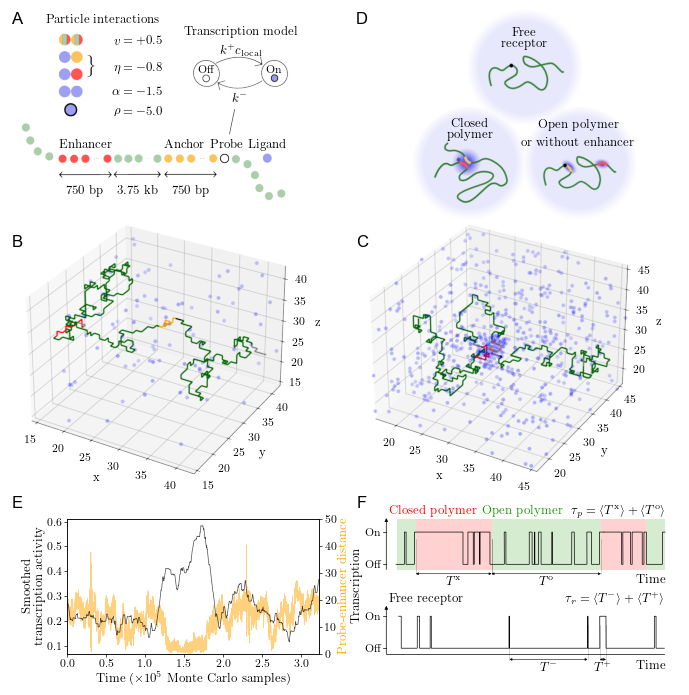

In [12]:
# ---- save, then composite the artwork underneath -------------------------------
OUT_DIR = "fig1"
path = os.path.join(OUT_DIR, "fig1.pdf")
fig1.savefig(path, format="pdf", transparent=True)
# no bbox_inches: that would re-crop the page and lose \textwidth.
# transparent=True: the artwork goes UNDER this layer, and matplotlib's white
# figure patch would otherwise cover it.
print("Saved figure to", path)


def _cairosvg():
    """cairosvg, or None if it cannot actually be used. `pip install cairosvg` on
    macOS leaves it importable but unusable (no cairo C library; cairocffi raises
    OSError, not ImportError), so every use falls back to Inkscape on any failure.
    Homebrew's cairo lives in /opt/homebrew/lib, which python.org Python never
    searches; point ctypes.util.find_library at it before the import."""
    import ctypes.util
    brew = "/opt/homebrew/lib/libcairo.2.dylib"
    if os.path.exists(brew) and not getattr(ctypes.util, "_brew_cairo", False):
        _find = ctypes.util.find_library
        ctypes.util.find_library = lambda name: (
            brew if name in ("cairo-2", "cairo", "libcairo-2") else _find(name))
        ctypes.util._brew_cairo = True
    try:
        import cairosvg
        return cairosvg
    except Exception:
        return None


def _inkscape():
    """Inkscape's CLI; on macOS an app bundle, not on PATH."""
    import shutil
    exe = shutil.which("inkscape")
    if exe:
        return exe
    for cand in ("/Applications/Inkscape.app/Contents/MacOS/inkscape",
                 os.path.expanduser("~/Applications/Inkscape.app/Contents/MacOS/inkscape")):
        if os.path.exists(cand):
            return cand
    return None


def svg_to_pdf(svg_path, pdf_path):
    """SVG -> PDF. The page box is read back by the caller, never assumed."""
    cs = _cairosvg()
    if cs is not None:
        try:
            cs.svg2pdf(url=svg_path, write_to=pdf_path)
            return "cairosvg"
        except Exception:
            pass
    import subprocess
    exe = _inkscape()
    if exe:
        subprocess.run([exe, svg_path, "--export-type=pdf", "--export-area-page",
                        "--export-filename=" + pdf_path], check=True, capture_output=True)
        return "inkscape"
    raise RuntimeError("no working SVG converter: install Inkscape, or cairosvg "
                       "plus the cairo C library (brew install cairo)")


def svg_to_png(svg_path, width_px):
    """SVG -> PNG bytes, for the inline preview only."""
    cs = _cairosvg()
    if cs is not None:
        try:
            return cs.svg2png(url=svg_path, output_width=width_px)
        except Exception:
            pass
    exe = _inkscape()
    if exe is None:
        return None
    import subprocess, tempfile
    tmp = os.path.join(tempfile.mkdtemp(), "preview.png")
    subprocess.run([exe, svg_path, "--export-type=png", "--export-area-page",
                    "--export-width=%d" % width_px, "--export-filename=" + tmp],
                   check=True, capture_output=True)
    data = open(tmp, "rb").read()
    os.remove(tmp)
    return data


def stamp_artwork(page_pdf, names):
    """Lay every art_*.pdf down on a blank page, at the rect art_rect() gives it,
    then put the transparent matplotlib layer over the top: type over drawing.
    The PDFs were converted once, by extract_art.py, so the result does not
    depend on the SVG renderer available here."""
    from pypdf import PdfReader, PdfWriter, Transformation, PageObject
    import shutil, tempfile
    scratch = tempfile.mkdtemp()               # intermediates never touch the repo
    out = PageObject.create_blank_page(width=W, height=H)
    for name in names:
        tmp, how = os.path.join(OUT_DIR, "art_%s.pdf" % name), "committed pdf"
        art = PdfReader(tmp).pages[0]
        bw, bh = float(art.mediabox.width), float(art.mediabox.height)
        x, y, w, h = art_rect(name)
        s = w / bw
        assert abs(h / bh - s) < 0.01 * s, "%s: non-uniform scale" % name
        out.merge_transformed_page(art, Transformation().scale(s).translate(x, y))
        print("  %-10s (%s) %5.1f x %5.1f pt at (%5.1f, %5.1f)" % (name, how, w, h, x, y))
    out.merge_page(PdfReader(page_pdf).pages[0])
    wr = PdfWriter(); wr.add_page(out)
    with open(page_pdf, "wb") as fh:
        wr.write(fh)
    shutil.rmtree(scratch, ignore_errors=True)


def _missing_deps():
    import importlib.util as iu
    missing = []
    if iu.find_spec("pypdf") is None:
        missing.append("pypdf")
    return missing                     # the art is stamped from committed PDFs


_missing = _missing_deps()
if _missing:
    print("\nThe artwork was NOT added: missing %s. The figure is saved without it.\n"
          "    pip install pypdf        # always needed\n"
          "    and either Inkscape, or: pip install cairosvg && brew install cairo\n"
          % ", ".join(_missing))
else:
    print("artwork:")
    stamp_artwork(path, ART)

# ---- inline preview: a raster copy of the artwork, added after savefig ---------
def preview_artwork(dpi=300):
    import io
    import matplotlib.image as mpimg
    for name in ART:
        x, y, w, h = art_rect(name)
        buf = svg_to_png(os.path.join(OUT_DIR, "art_%s.svg" % name), max(int(w / 72 * dpi), 1))
        if buf is None:
            return False
        ax = fig1.add_axes(_rect(x, y, w, h), zorder=-1)
        ax.imshow(mpimg.imread(io.BytesIO(buf), format="png"), interpolation="bilinear",
                  aspect="auto")
        ax.set_axis_off()
    return True


if not preview_artwork():
    print("(no inline preview of the artwork: neither cairosvg nor Inkscape found)")

from IPython.display import display
display(fig1)